## 1. General Imports

In [96]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import os 
import glob

## 2. Creating the merged dataset

In [97]:
base_url = "../../results/Splined/"
variables = ["A%","ALR(L)","ALR(S)","CE","CEC","L%","OC(%)","OM%","pH","S%"]
csv_files = sorted(glob.glob(os.path.join(base_url, "*.csv")))

dfs=[]

for index  , (file , var) in enumerate(zip(os.listdir(f"{base_url}") , variables)):
    df = pd.DataFrame()
    df_file = pd.read_csv(f"{base_url}/{file}")
    df["SID"] = df_file["SID"]
    df["UD"] = df_file["UD"]
    df["LD"]= df_file["LD"]
    df[var] = df_file["SPLINED_VALUE"]
    dfs.append(df)


In [98]:
dfs[0]

,SID,UD,LD,A%
0,-0.09455116238_35.78682408,0,5,12.333685
1,-0.09455116238_35.78682408,5,15,11.847969
2,-0.09455116238_35.78682408,15,30,9.743061
3,-0.09455116238_35.78682408,30,60,5.525814
4,-0.09455116238_35.78682408,60,100,4.621229
...,...,...,...,...
2529,8.414166667_37.09472222,5,15,0.100000
2530,8.414166667_37.09472222,15,30,0.100000
2531,8.414166667_37.09472222,30,60,0.100000
2532,8.414166667_37.09472222,60,100,0.100000


In [99]:
print(dfs[1].value_counts())

SID                         UD   LD   ALR(L)  
-0.09455116238_35.78682408  0    5    0.893930    1
3.686038889_32.26595278     15   30   0.000000    1
3.677452778_32.26458611     0    5    0.132544    1
                            5    15   0.153562    1
                            15   30   0.131502    1
                                                 ..
-1.45685_35.14747778        60   100  0.794480    1
                            100  200  0.797245    1
-1.457188889_35.12945       0    5    0.337515    1
                            5    15   0.339059    1
8.414166667_37.09472222     100  200  1.559496    1
Name: count, Length: 2449, dtype: int64


In [100]:
merged_df = pd.merge(dfs[0], dfs[1], on=['SID', 'UD', 'LD'], how='outer')

merged_df = pd.merge(merged_df, dfs[2], on=['SID', 'UD', 'LD'], how='outer')
merged_df = pd.merge(merged_df, dfs[3], on=['SID', 'UD', 'LD'], how='outer')
merged_df = pd.merge(merged_df, dfs[4], on=['SID', 'UD', 'LD'], how='outer')
merged_df = pd.merge(merged_df, dfs[5], on=['SID', 'UD', 'LD'], how='outer')
merged_df = pd.merge(merged_df, dfs[6], on=['SID', 'UD', 'LD'], how='outer')
merged_df = pd.merge(merged_df, dfs[7], on=['SID', 'UD', 'LD'], how='outer')
merged_df = pd.merge(merged_df, dfs[8], on=['SID', 'UD', 'LD'], how='outer')
df = pd.merge(merged_df, dfs[9], on=['SID', 'UD', 'LD'], how='outer')
df

,SID,UD,LD,A%,ALR(L),ALR(S),CE,CEC,L%,OC(%),OM%,pH,S%
0,-0.09455116238_35.78682408,0,5,12.333685,0.893930,2.306617,6.404642,7.311231,18.140976,NaN,NaN,7.110377,74.547794
1,-0.09455116238_35.78682408,5,15,11.847969,0.946038,2.353142,6.190028,7.048924,18.278750,NaN,NaN,7.144755,74.672326
2,-0.09455116238_35.78682408,15,30,9.743061,1.171362,2.554309,5.262191,5.915067,18.874708,NaN,NaN,7.293732,75.210226
3,-0.09455116238_35.78682408,30,60,5.525814,1.512805,2.855176,3.901625,4.290227,19.820767,NaN,NaN,7.591430,75.889006
4,-0.09455116238_35.78682408,60,100,4.621229,1.047307,2.419303,6.050623,7.109795,18.809306,NaN,NaN,7.651464,74.080899
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2736,8.414166667_37.09472222,5,15,0.100000,1.401231,2.420257,NaN,6.131968,24.892460,11.696769,NaN,6.177699,68.975573
2737,8.414166667_37.09472222,15,30,0.100000,1.423329,2.403869,NaN,6.165818,25.601487,14.661547,NaN,6.271719,68.232695
2738,8.414166667_37.09472222,30,60,0.100000,1.477367,2.372119,NaN,6.210706,27.210403,18.866199,NaN,6.405402,66.578892
2739,8.414166667_37.09472222,60,100,0.100000,1.535705,2.358143,NaN,6.166735,28.642714,15.976235,NaN,6.314960,65.190550


In [101]:
df[['X', 'Y']] = df['SID'].str.split('_', expand=True)
df['X'] = pd.to_numeric(df['X'])
df['Y'] = pd.to_numeric(df['Y'])
df

,SID,UD,LD,A%,ALR(L),ALR(S),CE,CEC,L%,OC(%),OM%,pH,S%,X,Y
0,-0.09455116238_35.78682408,0,5,12.333685,0.893930,2.306617,6.404642,7.311231,18.140976,NaN,NaN,7.110377,74.547794,-0.094551,35.786824
1,-0.09455116238_35.78682408,5,15,11.847969,0.946038,2.353142,6.190028,7.048924,18.278750,NaN,NaN,7.144755,74.672326,-0.094551,35.786824
2,-0.09455116238_35.78682408,15,30,9.743061,1.171362,2.554309,5.262191,5.915067,18.874708,NaN,NaN,7.293732,75.210226,-0.094551,35.786824
3,-0.09455116238_35.78682408,30,60,5.525814,1.512805,2.855176,3.901625,4.290227,19.820767,NaN,NaN,7.591430,75.889006,-0.094551,35.786824
4,-0.09455116238_35.78682408,60,100,4.621229,1.047307,2.419303,6.050623,7.109795,18.809306,NaN,NaN,7.651464,74.080899,-0.094551,35.786824
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2736,8.414166667_37.09472222,5,15,0.100000,1.401231,2.420257,NaN,6.131968,24.892460,11.696769,NaN,6.177699,68.975573,8.414167,37.094722
2737,8.414166667_37.09472222,15,30,0.100000,1.423329,2.403869,NaN,6.165818,25.601487,14.661547,NaN,6.271719,68.232695,8.414167,37.094722
2738,8.414166667_37.09472222,30,60,0.100000,1.477367,2.372119,NaN,6.210706,27.210403,18.866199,NaN,6.405402,66.578892,8.414167,37.094722
2739,8.414166667_37.09472222,60,100,0.100000,1.535705,2.358143,NaN,6.166735,28.642714,15.976235,NaN,6.314960,65.190550,8.414167,37.094722


## 3.oredering the columns

In [102]:
df = df[["SID" ,"X","Y","UD","LD","pH","CE","CEC","A%","L%","S%","ALR(L)","ALR(S)","OC(%)","OM%"]]
df

,SID,X,Y,UD,LD,pH,CE,CEC,A%,L%,S%,ALR(L),ALR(S),OC(%),OM%
0,-0.09455116238_35.78682408,-0.094551,35.786824,0,5,7.110377,6.404642,7.311231,12.333685,18.140976,74.547794,0.893930,2.306617,NaN,NaN
1,-0.09455116238_35.78682408,-0.094551,35.786824,5,15,7.144755,6.190028,7.048924,11.847969,18.278750,74.672326,0.946038,2.353142,NaN,NaN
2,-0.09455116238_35.78682408,-0.094551,35.786824,15,30,7.293732,5.262191,5.915067,9.743061,18.874708,75.210226,1.171362,2.554309,NaN,NaN
3,-0.09455116238_35.78682408,-0.094551,35.786824,30,60,7.591430,3.901625,4.290227,5.525814,19.820767,75.889006,1.512805,2.855176,NaN,NaN
4,-0.09455116238_35.78682408,-0.094551,35.786824,60,100,7.651464,6.050623,7.109795,4.621229,18.809306,74.080899,1.047307,2.419303,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2736,8.414166667_37.09472222,8.414167,37.094722,5,15,6.177699,NaN,6.131968,0.100000,24.892460,68.975573,1.401231,2.420257,11.696769,NaN
2737,8.414166667_37.09472222,8.414167,37.094722,15,30,6.271719,NaN,6.165818,0.100000,25.601487,68.232695,1.423329,2.403869,14.661547,NaN
2738,8.414166667_37.09472222,8.414167,37.094722,30,60,6.405402,NaN,6.210706,0.100000,27.210403,66.578892,1.477367,2.372119,18.866199,NaN
2739,8.414166667_37.09472222,8.414167,37.094722,60,100,6.314960,NaN,6.166735,0.100000,28.642714,65.190550,1.535705,2.358143,15.976235,NaN


In [103]:
df["OM%"] = df["OM%"].fillna(df["OC(%)"])

In [104]:
print(df.isna().sum())

SID          0
X            0
Y            0
UD           0
LD           0
pH          15
CE         576
CEC        232
A%         207
L%         279
S%         164
ALR(L)     292
ALR(S)     249
OC(%)     2143
OM%       1820
dtype: int64


In [105]:
df =df.drop(columns=["OC(%)"])

Ranges
15_30      530
30_60      520
0_5        519
5_15       519
60_100     407
100_200    246
Name: count, dtype: int64

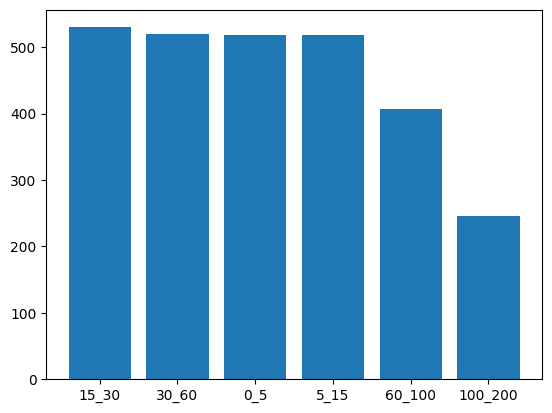

In [114]:
df["Ranges"] = df.apply(lambda row : f"{row['UD']}_{row['LD']}" , axis=1)
range_counts = df["Ranges"].value_counts()
plt.bar(range_counts.index, range_counts.values)
plt.show()

## 4. Add all unadded depths ranges

In [115]:
standard_depths = [(0, 5), (5, 15), (15, 30), (30, 60), (60, 100), (100, 200)]
unique_coords = df[['X', 'Y']].drop_duplicates()
full_rows = []
for _, row in unique_coords.iterrows():
    x, y = row['X'], row['Y']
    for ud, ld in standard_depths:
        full_rows.append({'X': x, 'Y': y, 'UD': ud, 'LD': ld})
full_df = pd.DataFrame(full_rows)
merged_df = pd.merge(full_df, df, on=['X', 'Y', 'UD', 'LD'], how='left')
merged_df['SID'] = merged_df['X'].astype(str) + "_" + merged_df['Y'].astype(str)
cols = ['SID', 'X', 'Y', 'UD', 'LD'] + [col for col in merged_df.columns if col not in ['SID', 'X', 'Y', 'UD', 'LD']]
merged_df = merged_df[cols]

merged_df

,SID,X,Y,UD,LD,pH,CE,CEC,A%,L%,S%,ALR(L),ALR(S),OM%,Ranges
0,-0.09455116238_35.78682408,-0.094551,35.786824,0,5,7.110377,6.404642,7.311231,12.333685,18.140976,74.547794,0.893930,2.306617,NaN,0_5
1,-0.09455116238_35.78682408,-0.094551,35.786824,5,15,7.144755,6.190028,7.048924,11.847969,18.278750,74.672326,0.946038,2.353142,NaN,5_15
2,-0.09455116238_35.78682408,-0.094551,35.786824,15,30,7.293732,5.262191,5.915067,9.743061,18.874708,75.210226,1.171362,2.554309,NaN,15_30
3,-0.09455116238_35.78682408,-0.094551,35.786824,30,60,7.591430,3.901625,4.290227,5.525814,19.820767,75.889006,1.512805,2.855176,NaN,30_60
4,-0.09455116238_35.78682408,-0.094551,35.786824,60,100,7.651464,6.050623,7.109795,4.621229,18.809306,74.080899,1.047307,2.419303,NaN,60_100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3181,8.414166667_37.09472222,8.414167,37.094722,5,15,6.177699,NaN,6.131968,0.100000,24.892460,68.975573,1.401231,2.420257,11.696769,5_15
3182,8.414166667_37.09472222,8.414167,37.094722,15,30,6.271719,NaN,6.165818,0.100000,25.601487,68.232695,1.423329,2.403869,14.661547,15_30
3183,8.414166667_37.09472222,8.414167,37.094722,30,60,6.405402,NaN,6.210706,0.100000,27.210403,66.578892,1.477367,2.372119,18.866199,30_60
3184,8.414166667_37.09472222,8.414167,37.094722,60,100,6.314960,NaN,6.166735,0.100000,28.642714,65.190550,1.535705,2.358143,15.976235,60_100


In [116]:
merged_df.to_csv("../../results/Soil/full_splined.csv")

## 5. Treating the missing values

In [117]:
import pandas as pd
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

numeric_df = merged_df.select_dtypes(include=['float64', 'int64'])
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_df)

imputer = KNNImputer(n_neighbors=5)
imputed_array = imputer.fit_transform(scaled_data)
real_values = scaler.inverse_transform(imputed_array)
merged_df[numeric_df.columns] = real_values
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3186 entries, 0 to 3185
Data columns (total 15 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SID     3186 non-null   object 
 1   X       3186 non-null   float64
 2   Y       3186 non-null   float64
 3   UD      3186 non-null   float64
 4   LD      3186 non-null   float64
 5   pH      3186 non-null   float64
 6   CE      3186 non-null   float64
 7   CEC     3186 non-null   float64
 8   A%      3186 non-null   float64
 9   L%      3186 non-null   float64
 10  S%      3186 non-null   float64
 11  ALR(L)  3186 non-null   float64
 12  ALR(S)  3186 non-null   float64
 13  OM%     3186 non-null   float64
 14  Ranges  2741 non-null   object 
dtypes: float64(13), object(2)
memory usage: 373.5+ KB


In [118]:
merged_df.to_csv("../../results/Soil/full_splined_NAN.csv")

In [119]:
uniques = merged_df.drop_duplicates(subset=["X","Y"])
uniques

,SID,X,Y,UD,LD,pH,CE,CEC,A%,L%,S%,ALR(L),ALR(S),OM%,Ranges
0,-0.09455116238_35.78682408,-0.094551,35.786824,0.0,5.0,7.110377,6.404642,7.311231,12.333685,18.140976,74.547794,0.893930,2.306617,0.533126,0_5
6,-0.09468234954_35.78322222,-0.094682,35.783222,0.0,5.0,7.576187,6.028645,8.795516,4.101079,7.912891,83.291593,0.000000,2.247701,0.567299,0_5
12,-0.09481351342_35.77962036,-0.094814,35.779620,0.0,5.0,7.557264,5.292950,6.339849,4.232644,23.833469,69.783936,1.329243,2.392225,0.745866,0_5
18,-0.09494465404_35.7760185,-0.094945,35.776018,0.0,5.0,7.668368,3.400624,3.270652,14.641522,50.034298,46.695050,2.763003,2.696493,0.676091,0_5
24,-0.09507577138_35.77241663,-0.095076,35.772417,0.0,5.0,7.051867,2.440479,1.517456,9.439977,39.378934,59.103610,3.200028,3.605780,0.653315,0_5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3156,7.698333333_36.78111111,7.698333,36.781111,0.0,5.0,8.299528,383.853774,30.381132,0.099906,38.016981,27.490613,0.224196,0.000000,1.004885,0_5
3162,7.9925_36.84861111,7.992500,36.848611,0.0,5.0,5.687539,28.007083,4.610997,0.121828,26.872473,68.516530,1.761085,2.698702,48.783917,0_5
3168,8.2_36.9,8.200000,36.900000,0.0,5.0,5.614928,23.527257,3.171597,0.100015,42.066458,54.761945,2.579962,2.843597,34.722968,0_5
3174,8.386666667_37.06444444,8.386667,37.064444,0.0,5.0,5.094341,27.049788,12.245741,0.100000,24.879419,62.874878,0.708640,1.635620,27.972723,0_5


In [120]:
df=merged_df

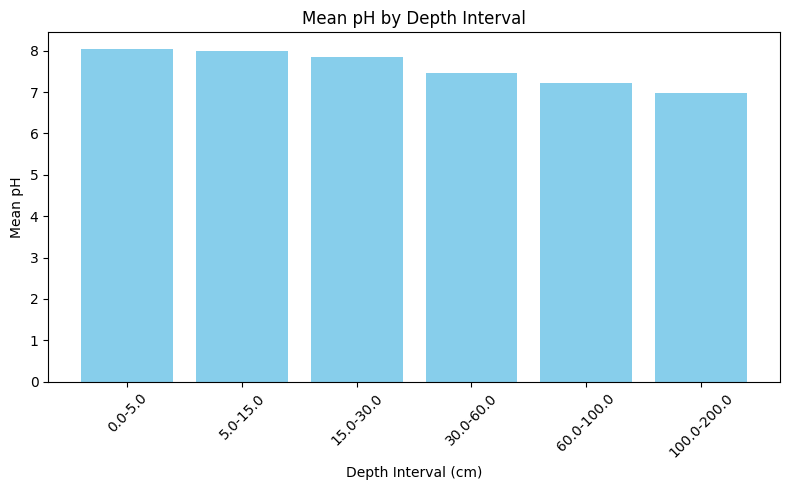

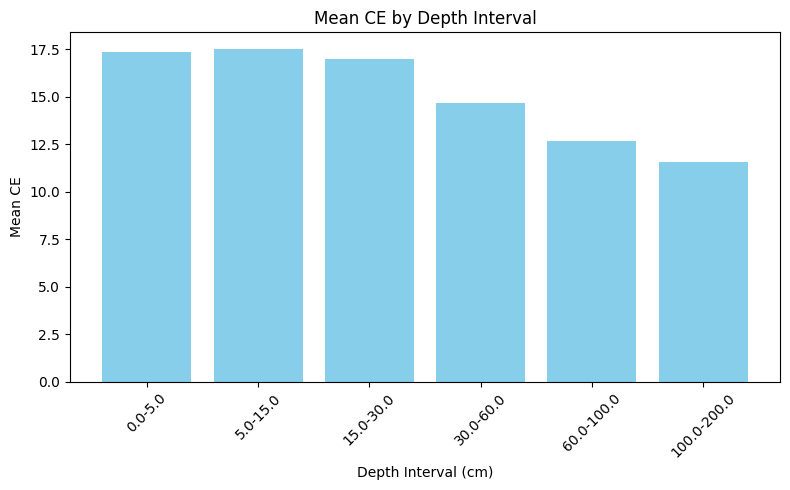

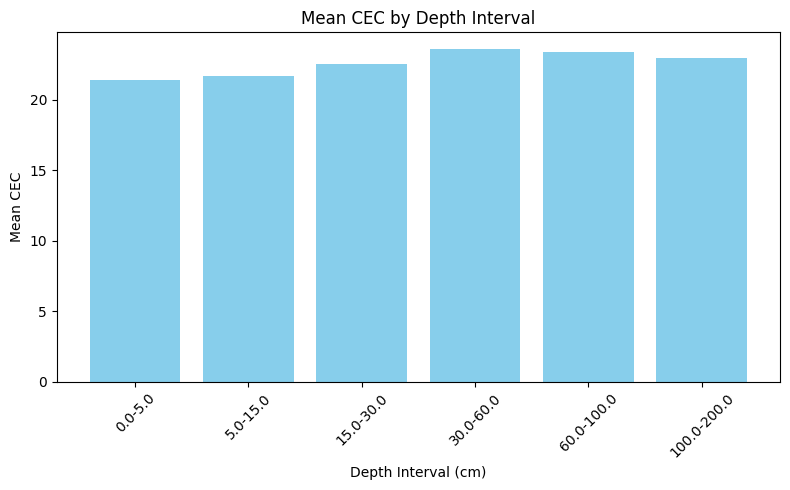

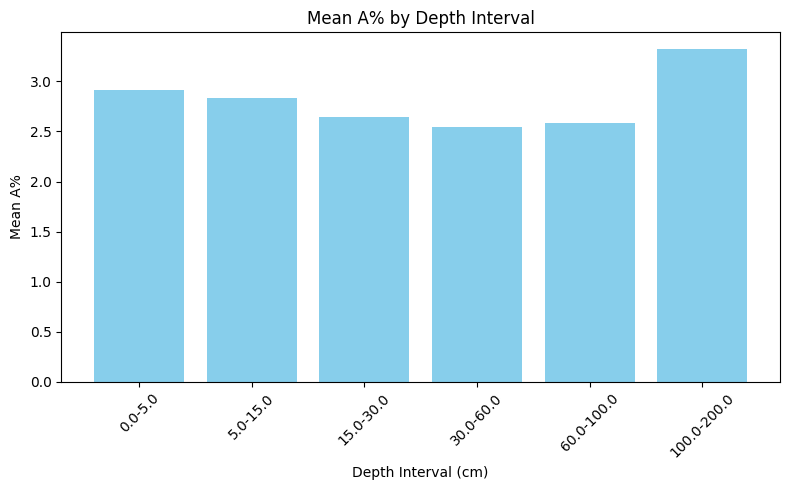

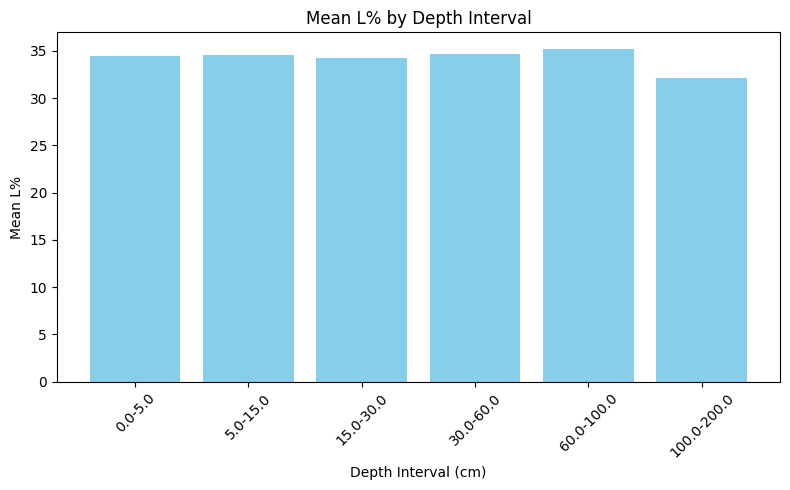

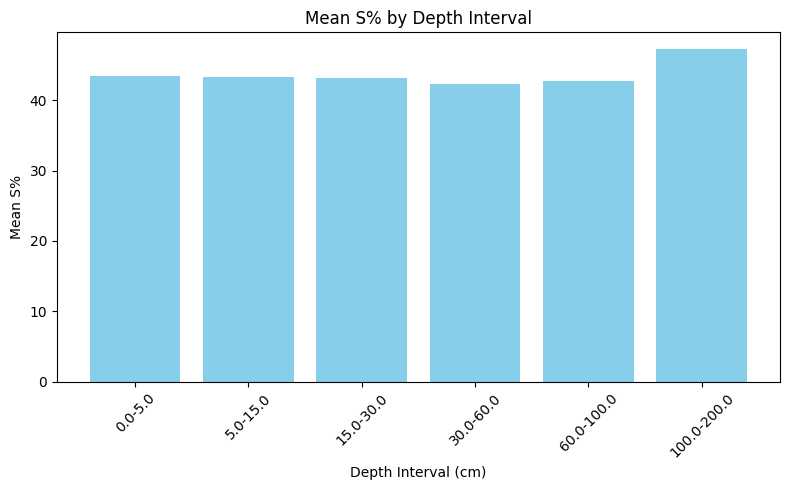

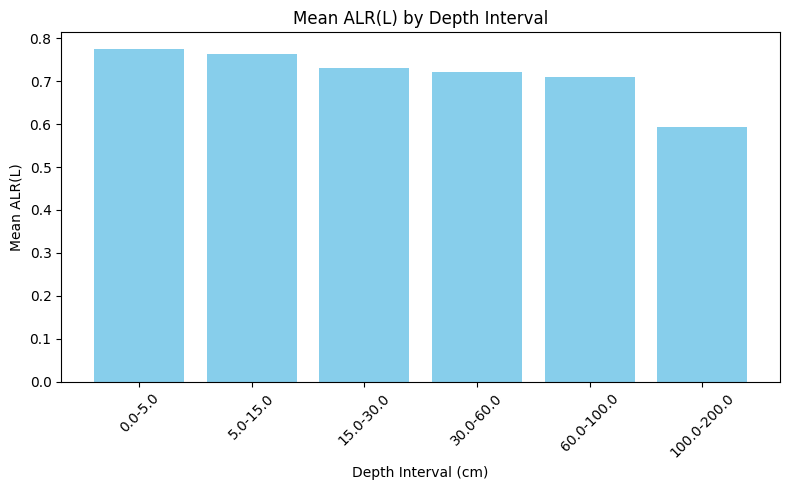

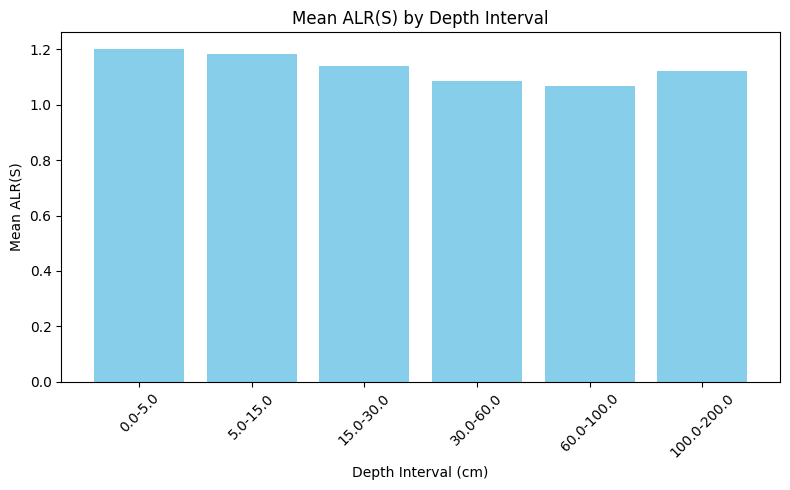

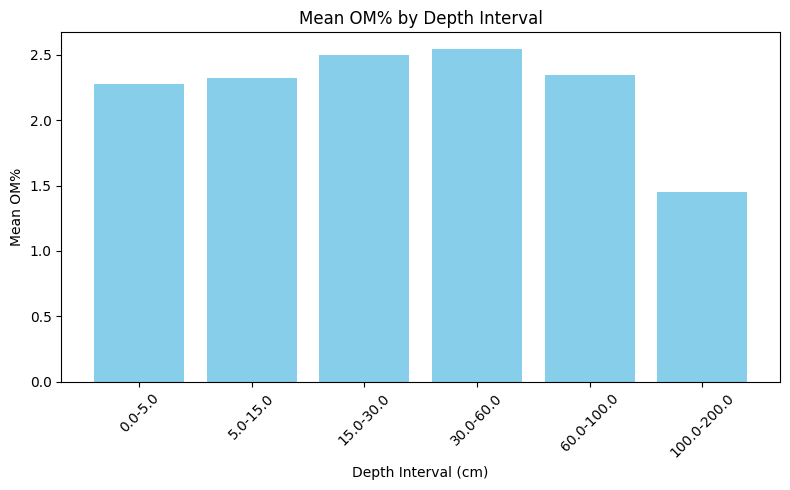

In [122]:
for i in df.columns : 
    if i not in ["SID" , "X" , "Y" , "UD","LD" , "Ranges"]:
        depth_summary = df.groupby(['UD', 'LD'])[i].mean().reset_index()
        depth_summary['depth_label'] = depth_summary['UD'].astype(str) + '-' + depth_summary['LD'].astype(str)
        plt.figure(figsize=(8, 5))
        plt.bar(depth_summary['depth_label'], depth_summary[i], color='skyblue')
        plt.xlabel('Depth Interval (cm)')
        plt.ylabel(f'Mean {i}')
        plt.title(f'Mean {i} by Depth Interval')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

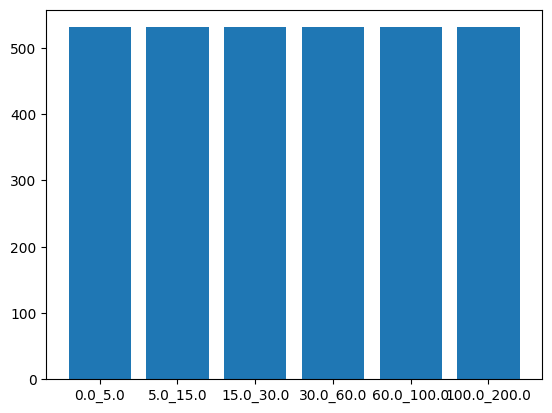

In [123]:
df["Ranges"] = df.apply(lambda row : f"{row['UD']}_{row['LD']}" , axis=1)
range_counts = df["Ranges"].value_counts()
plt.bar(range_counts.index, range_counts.values)
plt.show()